In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the Dataset

df = pd.read_excel("../Dataset/disaster_tweets.csv.xlsx")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


In [3]:

# Step 3: Understand Dataset Structure

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   str   
 2   location  5079 non-null   object
 3   text      7613 non-null   str   
 4   target    7613 non-null   int64 
dtypes: int64(2), object(1), str(2)
memory usage: 1.1+ MB

Missing Values:
id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

Statistical Summary:


,id,keyword,location,text,target
count,7613.000000,7552,5079,7613,7613.00000
unique,NaN,221,3293,7503,NaN
top,NaN,fatalities,USA,11-Year-Old Boy Charged With Manslaughter of Toddler: Report: An 11-year-old boy has been charge...,NaN
freq,NaN,45,105,10,NaN
mean,5441.934848,NaN,NaN,NaN,0.42966
std,3137.116090,NaN,NaN,NaN,0.49506
min,1.000000,NaN,NaN,NaN,0.00000
25%,2734.000000,NaN,NaN,NaN,0.00000
50%,5408.000000,NaN,NaN,NaN,0.00000
75%,8146.000000,NaN,NaN,NaN,1.00000


In [4]:

import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())


Current Working Directory:
d:\DigiCrome Academy\Internship\Nexthikes\P7\Notebooks

Files and folders available:
['01_data_exploration.ipynb']


In [5]:

from pathlib import Path

csv_files = list(Path.cwd().parent.rglob("disaster_tweets.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.resolve())



CSV files found: 0


In [6]:

from pathlib import Path

downloads = Path.home() / "Downloads"

print("Files in Downloads folder:")

for file in downloads.glob("*.csv"):
    print(file.name)


Files in Downloads folder:
1772893076.csv
2.csv
lecture 6 dataset.csv


Target Distribution:
target
0    4342
1    3271
Name: count, dtype: int64

Percentage Distribution:
target
0    57.034021
1    42.965979
Name: proportion, dtype: float64


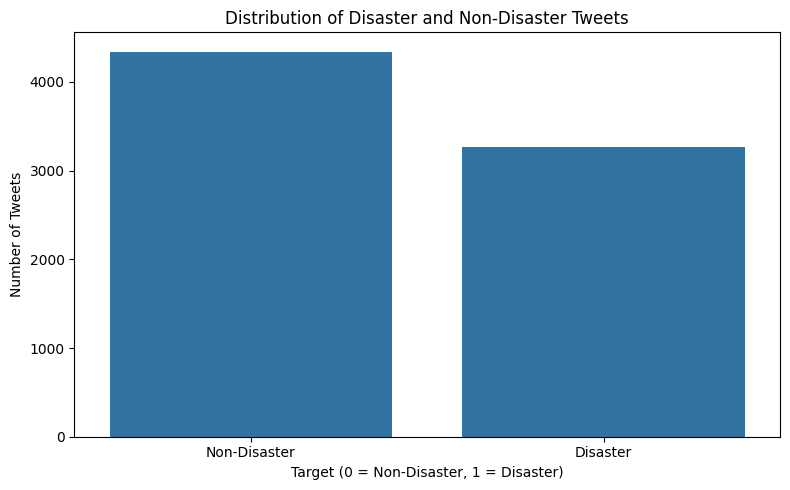

In [7]:

# Step 4: Target Class Distribution

target_counts = df["target"].value_counts().sort_index()

print("Target Distribution:")
print(target_counts)

print("\nPercentage Distribution:")
print((df["target"].value_counts(normalize=True) * 100).sort_index())

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="target")

plt.title("Distribution of Disaster and Non-Disaster Tweets")
plt.xlabel("Target (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Number of Tweets")

plt.xticks([0, 1], ["Non-Disaster", "Disaster"])
plt.tight_layout()
plt.show()


Top 15 Keywords in Disaster Tweets:


keyword
derailment             39
outbreak               39
wreckage               39
debris                 37
oil%20spill            37
typhoon                37
evacuated              32
rescuers               32
suicide%20bomb         32
suicide%20bombing      32
nuclear%20disaster     31
razed                  31
airplane%20accident    30
earthquake             30
suicide%20bomber       30
Name: count, dtype: int64

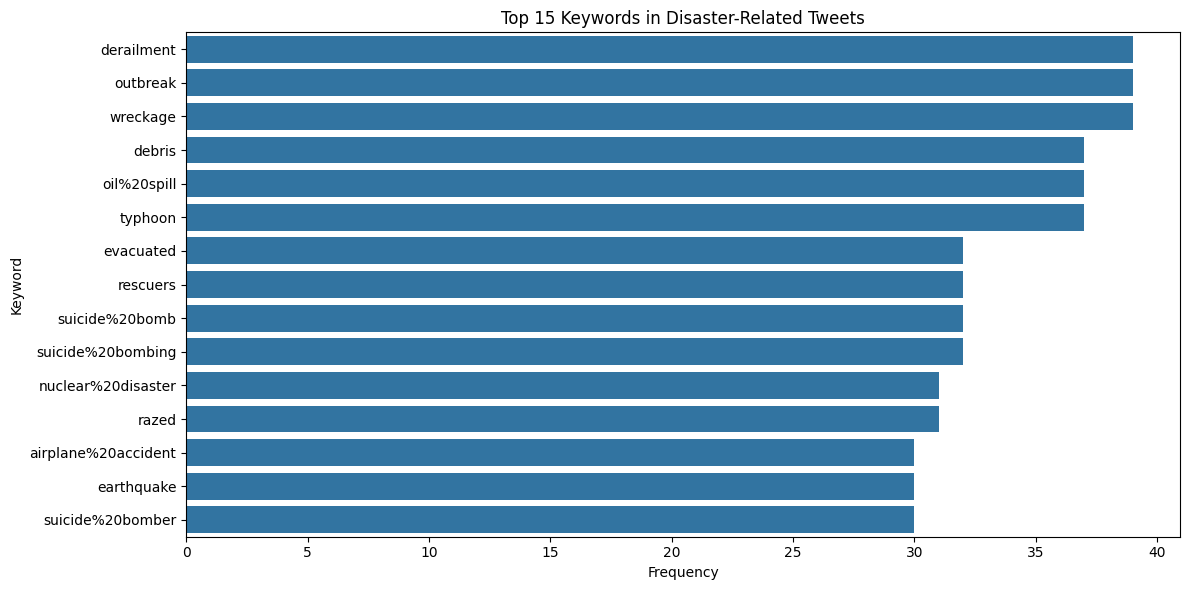

In [8]:

# Step 5: Most Frequent Disaster Keywords

disaster_keywords = df[df["target"] == 1]["keyword"]

top_keywords = disaster_keywords.value_counts().head(15)

print("Top 15 Keywords in Disaster Tweets:")
display(top_keywords)

# Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_keywords.values,
    y=top_keywords.index
)

plt.title("Top 15 Keywords in Disaster-Related Tweets")
plt.xlabel("Frequency")
plt.ylabel("Keyword")

plt.tight_layout()
plt.show()


Tweet Length Statistics:
count    7613.000000
mean      101.681203
std        34.352859
min         7.000000
25%        78.000000
50%       107.000000
75%       134.000000
max       190.000000
Name: tweet_length, dtype: float64


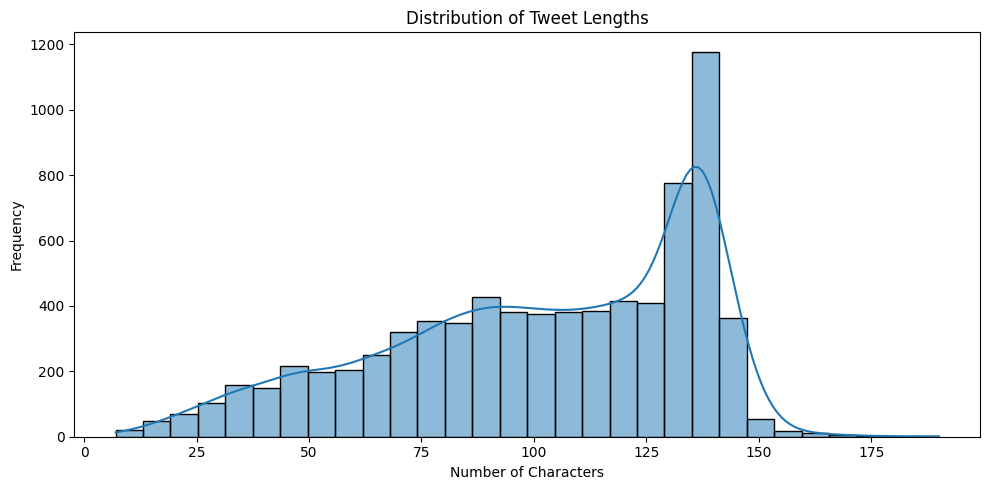

In [9]:

# Step 6: Tweet Length Analysis

df["tweet_length"] = df["text"].apply(len)

print("Tweet Length Statistics:")
print(df["tweet_length"].describe())

# Visualize tweet length distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tweet_length",
    bins=30,
    kde=True
)

plt.title("Distribution of Tweet Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


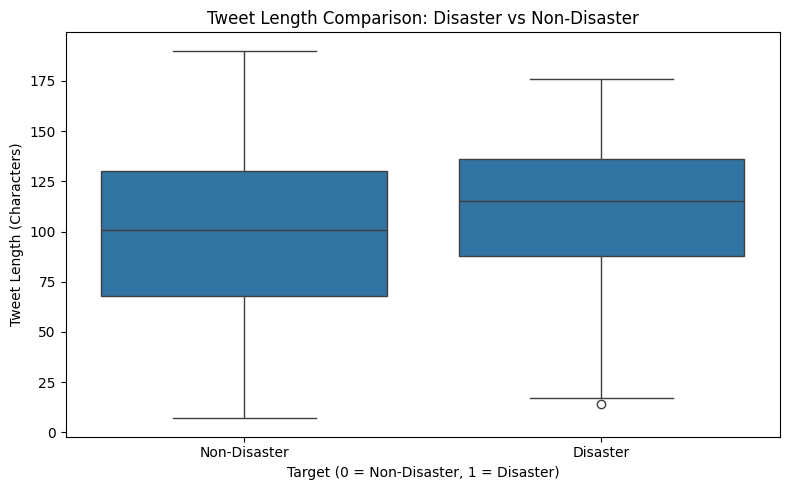

In [10]:

# Step 7: Tweet Length by Target Class

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="tweet_length"
)

plt.title("Tweet Length Comparison: Disaster vs Non-Disaster")
plt.xlabel("Target (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Tweet Length (Characters)")

plt.xticks([0, 1], ["Non-Disaster", "Disaster"])

plt.tight_layout()
plt.show()



## Data Exploration Summary

### 1. Dataset Overview
- Total records: 7,613
- Total columns: 5
- Missing keyword values: 61
- Missing location values: 2,534

### 2. Target Distribution
- Non-disaster tweets: 4,342 (57.03%)
- Disaster tweets: 3,271 (42.97%)

### 3. Keyword Analysis
The most frequent disaster-related keywords include derailment,
outbreak, wreckage, debris, oil spill and typhoon.

### 4. Tweet Length Analysis
- Average tweet length: 101.68 characters
- Median tweet length: 107 characters
- Minimum length: 7 characters
- Maximum length: 190 characters

### 5. Initial Findings
The dataset contains both disaster and non-disaster tweets.
The target classes are reasonably balanced. Text preprocessing
will be required before feature extraction and model training.


In [11]:

# Step 8: Text Cleaning

import re

def clean_tweet(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove Twitter usernames
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbols but keep words
    text = re.sub(r"#", "", text)

    # Remove special characters and punctuation
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Create a cleaned text column
df["clean_text"] = df["text"].apply(clean_tweet)

print("Text cleaning completed!")

# Compare original and cleaned tweets
display(df[["text", "clean_text"]].head(10))


Text cleaning completed!


,text,clean_text
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,our deeds are the reason of this earthquake may allah forgive us all
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or...,all residents asked to shelter in place are being notified by officers no other evacuation or sh...
3,"13,000 people receive #wildfires evacuation orders in California",13 000 people receive wildfires evacuation orders in california
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,just got sent this photo from ruby alaska as smoke from wildfires pours into a school
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAf...,rockyfire update california hwy 20 closed in both directions due to lake county fire cafire wild...
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas
7,I'm on top of the hill and I can see a fire in the woods...,i m on top of the hill and i can see a fire in the woods
8,There's an emergency evacuation happening now in the building across the street,there s an emergency evacuation happening now in the building across the street
9,I'm afraid that the tornado is coming to our area...,i m afraid that the tornado is coming to our area


In [12]:

# Step 9: Tokenization

df["tokens"] = df["clean_text"].apply(lambda text: text.split())

print("Tokenization completed!")

display(df[["clean_text", "tokens"]].head(10))


Tokenization completed!


,clean_text,tokens
0,our deeds are the reason of this earthquake may allah forgive us all,"[our, deeds, are, the, reason, of, this, earthquake, may, allah, forgive, us, all]"
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are being notified by officers no other evacuation or sh...,"[all, residents, asked, to, shelter, in, place, are, being, notified, by, officers, no, other, e..."
3,13 000 people receive wildfires evacuation orders in california,"[13, 000, people, receive, wildfires, evacuation, orders, in, california]"
4,just got sent this photo from ruby alaska as smoke from wildfires pours into a school,"[just, got, sent, this, photo, from, ruby, alaska, as, smoke, from, wildfires, pours, into, a, s..."
5,rockyfire update california hwy 20 closed in both directions due to lake county fire cafire wild...,"[rockyfire, update, california, hwy, 20, closed, in, both, directions, due, to, lake, county, fi..."
6,flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas,"[flood, disaster, heavy, rain, causes, flash, flooding, of, streets, in, manitou, colorado, spri..."
7,i m on top of the hill and i can see a fire in the woods,"[i, m, on, top, of, the, hill, and, i, can, see, a, fire, in, the, woods]"
8,there s an emergency evacuation happening now in the building across the street,"[there, s, an, emergency, evacuation, happening, now, in, the, building, across, the, street]"
9,i m afraid that the tornado is coming to our area,"[i, m, afraid, that, the, tornado, is, coming, to, our, area]"


In [13]:

# Step 10: Train-Test Split

from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Train-Test Split Completed!

Training Data Shape: (6090,)
Testing Data Shape: (1523,)

Training Target Distribution:
target
0    57.027915
1    42.972085
Name: proportion, dtype: float64

Testing Target Distribution:
target
0    57.058437
1    42.941563
Name: proportion, dtype: float64


In [14]:

# Step 11: Verify Dataset Split

print("Total Original Records:", len(df))
print("Total Training Records:", len(X_train))
print("Total Testing Records:", len(X_test))

assert len(X_train) + len(X_test) == len(df)

print("\nDataset split verified successfully!")


Total Original Records: 7613
Total Training Records: 6090
Total Testing Records: 1523

Dataset split verified successfully!


In [15]:

# Step 12: TF-IDF Feature Extraction

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Feature Extraction Completed!")

print("\nTraining TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("\nTotal Features:", len(tfidf.get_feature_names_out()))

print("\nSample Features:")
print(tfidf.get_feature_names_out()[:20])


TF-IDF Feature Extraction Completed!

Training TF-IDF Shape: (6090, 10000)
Testing TF-IDF Shape: (1523, 10000)

Total Features: 10000

Sample Features:
['00' '00 11' '00 at' '00 pm' '000' '01' '01 04' '01 10' '01 utc2015' '02'
 '02 scene' '03' '04' '04 01' '04 utc' '05' '05 15' '05 16' '05 17'
 '05 2015']


In [16]:

# Step 13: Model Selection and Training

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train all models
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")



Training Logistic Regression...
Logistic Regression trained successfully!

Training Multinomial Naive Bayes...
Multinomial Naive Bayes trained successfully!

Training Random Forest...
Random Forest trained successfully!

All models trained successfully!


In [17]:

# Step 14: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

    print(f"\n{'='*50}")
    print(name)
    print("="*50)

    print(classification_report(y_test, y_pred))

# Create comparison table
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)



Logistic Regression
              precision    recall  f1-score   support

           0       0.81      0.90      0.85       869
           1       0.85      0.71      0.77       654

    accuracy                           0.82      1523
   macro avg       0.83      0.81      0.81      1523
weighted avg       0.82      0.82      0.82      1523


Multinomial Naive Bayes
              precision    recall  f1-score   support

           0       0.78      0.94      0.85       869
           1       0.89      0.66      0.76       654

    accuracy                           0.82      1523
   macro avg       0.84      0.80      0.81      1523
weighted avg       0.83      0.82      0.81      1523


Random Forest
              precision    recall  f1-score   support

           0       0.77      0.90      0.83       869
           1       0.83      0.64      0.72       654

    accuracy                           0.79      1523
   macro avg       0.80      0.77      0.77      1523
weighted avg 

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.820092,0.846715,0.709480,0.772047
1,Multinomial Naive Bayes,0.817466,0.888430,0.657492,0.755712
2,Random Forest,0.787919,0.829026,0.637615,0.720830


In [18]:

# Step 15: Cross-Validation

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

cv_results = []

for name, model in cv_models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean F1 Score": scores.mean(),
        "Standard Deviation": scores.std()
    })

    print(f"\n{name}")
    print("Fold Scores:", scores)
    print("Mean F1:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="Mean F1 Score",
        ascending=False
    ).reset_index(drop=True)
)



Logistic Regression
Fold Scores: [0.73772205 0.75282051 0.71581197 0.75343915 0.74082073]
Mean F1: 0.7401
Standard Deviation: 0.0137

Multinomial Naive Bayes
Fold Scores: [0.71238938 0.7372973  0.6854566  0.72873563 0.71672355]
Mean F1: 0.7161
Standard Deviation: 0.0177

Random Forest
Fold Scores: [0.70575221 0.73752711 0.68707483 0.70251716 0.69703872]
Mean F1: 0.706
Standard Deviation: 0.017


,Model,Mean F1 Score,Standard Deviation
0,Logistic Regression,0.740123,0.013681
1,Multinomial Naive Bayes,0.716120,0.017676
2,Random Forest,0.705982,0.016998


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.1, 0.5, 1, 2, 5, 10],
    "classifier__solver": ["liblinear", "lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best Cross-Validation F1 Score: 0.7495


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Logistic Regression Results")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Logistic Regression Results
----------------------------------
Accuracy: 0.8004
Precision: 0.7676
Recall: 0.7676
F1 Score: 0.7676

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       869
           1       0.77      0.77      0.77       654

    accuracy                           0.80      1523
   macro avg       0.80      0.80      0.80      1523
weighted avg       0.80      0.80      0.80      1523



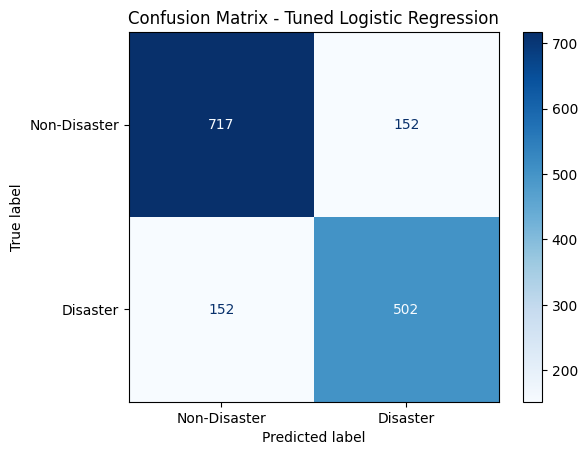

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Disaster", "Disaster"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

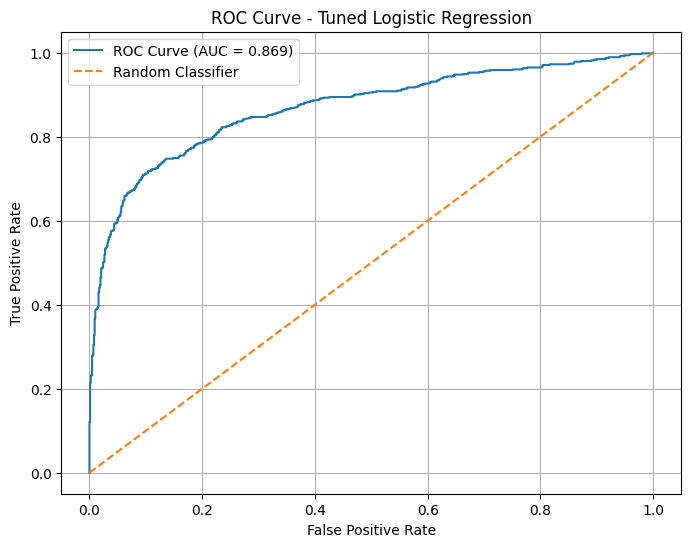

ROC-AUC Score: 0.8686


In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

In [23]:
print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8686


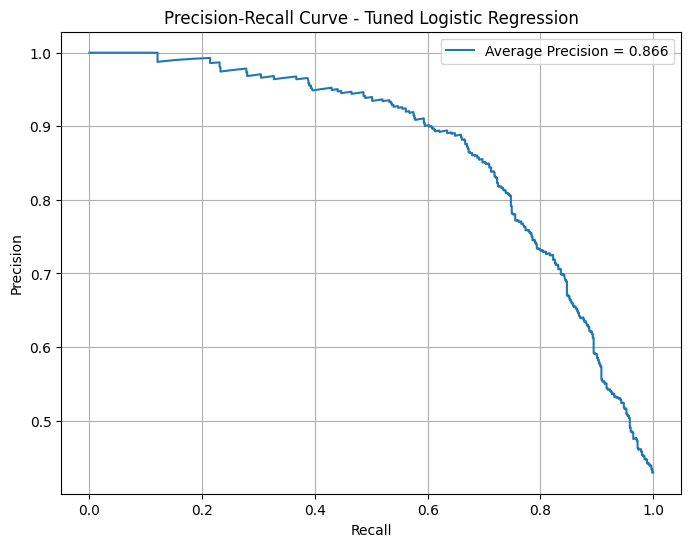

Average Precision Score: 0.8662


In [24]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

avg_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"Average Precision = {avg_precision:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Tuned Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("Average Precision Score:", round(avg_precision, 4))

In [25]:
print("Average Precision Score:", round(avg_precision, 4))

Average Precision Score: 0.8662


In [26]:
comparison_df = results_df.copy()

tuned_results = pd.DataFrame([{
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1 Score": f1_score(y_test, y_pred_tuned)
}])

comparison_df = pd.concat(
    [comparison_df, tuned_results],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8201,0.8467,0.7095,0.7720
1,Tuned Logistic Regression,0.8004,0.7676,0.7676,0.7676
2,Multinomial Naive Bayes,0.8175,0.8884,0.6575,0.7557
3,Random Forest,0.7879,0.8290,0.6376,0.7208


In [27]:
sample_tweets = [
    "There is a massive earthquake in the city",
    "I am enjoying a beautiful sunny day",
    "Emergency teams are rescuing people after the flood",
    "Having a wonderful time with my family"
]

sample_cleaned = [clean_tweet(tweet) for tweet in sample_tweets]

sample_tfidf = tfidf.transform(sample_cleaned)

sample_predictions = trained_models["Logistic Regression"].predict(sample_tfidf)

for tweet, prediction in zip(sample_tweets, sample_predictions):
    label = "Disaster" if prediction == 1 else "Non-Disaster"
    print("Tweet:", tweet)
    print("Prediction:", label)
    print("-" * 60)

Tweet: There is a massive earthquake in the city
Prediction: Disaster
------------------------------------------------------------
Tweet: I am enjoying a beautiful sunny day
Prediction: Non-Disaster
------------------------------------------------------------
Tweet: Emergency teams are rescuing people after the flood
Prediction: Disaster
------------------------------------------------------------
Tweet: Having a wonderful time with my family
Prediction: Non-Disaster
------------------------------------------------------------


In [28]:
from sklearn.metrics import accuracy_score, f1_score

lr_model = trained_models["Logistic Regression"]

train_predictions = lr_model.predict(X_train_tfidf)
test_predictions = lr_model.predict(X_test_tfidf)

print("Training Performance")
print("--------------------")
print("Accuracy:", round(accuracy_score(y_train, train_predictions), 4))
print("F1 Score:", round(f1_score(y_train, train_predictions), 4))

print("\nTesting Performance")
print("-------------------")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("F1 Score:", round(f1_score(y_test, test_predictions), 4))

Training Performance
--------------------
Accuracy: 0.8773
F1 Score: 0.844

Testing Performance
-------------------
Accuracy: 0.8201
F1 Score: 0.772


In [29]:
import os
import joblib

os.makedirs("../Models", exist_ok=True)

joblib.dump(
    trained_models["Logistic Regression"],
    "../Models/logistic_regression_model.pkl"
)

joblib.dump(
    tfidf,
    "../Models/tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [30]:
import joblib

loaded_model = joblib.load("../Models/logistic_regression_model.pkl")
loaded_tfidf = joblib.load("../Models/tfidf_vectorizer.pkl")

test_tweet = "A massive flood has affected several villages"

cleaned_tweet = clean_tweet(test_tweet)

tweet_vector = loaded_tfidf.transform([cleaned_tweet])

prediction = loaded_model.predict(tweet_vector)[0]

result = "Disaster" if prediction == 1 else "Non-Disaster"

print("Original Tweet:", test_tweet)
print("Prediction:", result)
print("Saved model loaded and tested successfully!")

Original Tweet: A massive flood has affected several villages
Prediction: Disaster
Saved model loaded and tested successfully!
